<a href="https://colab.research.google.com/github/polinkabaranova/recsys-tutor/blob/main/recsys_tutor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Подбор задач для ученика: рекомендательная система

**Задача.** Подсказать школьнику, какие задачи по математике решать дальше: из тем, где у него пробелы, и такой сложности, чтобы он скорее справился, но не слишком легко. Целевой шанс решить около 70% - задача чуть выше того, что ученик уже уверенно умеет (в педагогике это называют зоной ближайшего развития).

**Данные.** [ASSISTments 2009–2010 Skill Builder](https://sites.google.com/site/assistmentsdata/home/2009-2010-assistment-data/skill-builder-data-2009-2010), исправленная версия. Это открытый набор ответов американских школьников на задачи по математике в онлайн-системе ASSISTments. Одна строка - один ответ ученика на одну задачу.

**Как запустить.** «Среда выполнения» → «Выполнить все». Данные скачаются автоматически.

**План**
1. Загрузка и чистка данных
2. Трудные и лёгкие темы
3. Бейзлайн: задачи из самой слабой темы
4. Признаки для модели
5. Разбиение на обучение и проверку
6. Модели и метрики
7. Офлайн-проверка рекомендаций
8. Рекомендации модели для ученика
9. Выводы, ограничения и что дальше

## 1. Загрузка и чистка данных

In [1]:
!gdown 1NNXHFRxcArrU0ZJSb9BIL56vmUt5FhlE -O data.csv

Downloading...
From: https://drive.google.com/uc?id=1NNXHFRxcArrU0ZJSb9BIL56vmUt5FhlE
To: /content/data.csv
100% 64.4M/64.4M [00:00<00:00, 124MB/s]


In [2]:
import numpy as np
import pandas as pd

df = pd.read_csv("data.csv", encoding="latin1", low_memory=False)
df.shape

(346860, 31)

In [3]:
# русские названия столбцов для показа таблиц (в коде остаются английские)
names = {
    "order_id": "номер записи", "user_id": "ученик", "problem_id": "задача",
    "skill_name": "тема", "correct": "решил",
    "user_count": "задач до этого", "user_right": "верных до этого",
    "user_acc": "доля верных (всего)",
    "skill_count": "задач по теме до этого", "skill_right": "верных по теме до этого",
    "skill_acc": "доля верных (по теме)", "skill_count_log": "опыт по теме",
    "problem_acc": "доля верных на задаче", "mean": "доля верных", "count": "ответов",
}

def ru(table):
    table = table.rename(columns=names)
    return table.rename_axis(names.get(table.index.name, table.index.name))

In [4]:
# нужные столбцы: номер записи, ученик, задача, тема, решил ли с первой попытки (1 — да, 0 — нет)
data = df[["order_id", "user_id", "problem_id", "skill_name", "correct"]]
print("Строк без темы:", data["skill_name"].isna().sum())

# убираем строки без темы и ставим ответы в порядке их записи в системе
data = data.dropna(subset=["skill_name"])
data = data.sort_values("order_id").reset_index(drop=True)

print("Строк после чистки:", len(data))
print("Учеников:", data["user_id"].nunique())
print("Задач:", data["problem_id"].nunique())
print("Тем:", data["skill_name"].nunique())
print("Доля верных ответов:", round(data["correct"].mean(), 3))

Строк без темы: 72270
Строк после чистки: 274590
Учеников: 4151
Задач: 16891
Тем: 101
Доля верных ответов: 0.662


Около пятой части строк не имеют темы, их убираем: без темы нельзя понять, в чём у ученика пробел.

Верным считается ответ **с первой попытки**. Если ученик ошибся, а потом исправился, или взял подсказку, в данных стоит 0.

## 2. Трудные и лёгкие темы

Считаем долю верных ответов по каждой теме. Темы, где меньше 100 ответов, не учитываем: по нескольким ответам выводы ненадёжны (например, у темы с 5 ответами доля верных 0%, но это может быть один слабый ученик).

In [5]:
topics = data.groupby("skill_name")["correct"].agg(["mean", "count"])
big_topics = topics[topics["count"] >= 100]
print("Тем со 100+ ответами:", len(big_topics))

# самые трудные темы
ru(big_topics.sort_values("mean").head(10))

Тем со 100+ ответами: 86


,доля верных,ответов
тема,,
Rotations,0.135831,427
Solving Systems of Linear Equations,0.192308,234
Surface Area Cylinder,0.315682,491
Percents,0.333333,117
Algebraic Solving,0.367609,389
Reflection,0.372549,459
Mean,0.446721,732
Unit Rate,0.464656,3183
Write Linear Equation from Graph,0.477584,5398


In [6]:
# самые лёгкие темы
ru(big_topics.sort_values("mean", ascending=False).head(10))

,доля верных,ответов
тема,,
Nets of 3D Figures,0.950000,280
Area Parallelogram,0.921739,115
Write Linear Equation from Situation,0.897351,906
Congruence,0.894378,587
Scatter Plot,0.869285,1859
Area Rectangle,0.862626,495
Area Triangle,0.856643,286
D.4.8-understanding-concept-of-probabilities,0.846491,456
Volume Rectangular Prism,0.840173,926


**Гипотеза для проверки.** «Составить уравнение прямой по графику» (Write Linear Equation from Graph) решают верно примерно в половине случаев, а «составить уравнение прямой по текстовой задаче» (from Situation) - примерно в 9 случаях из 10. Можно было бы ожидать обратного. Возможная причина - разные задачи внутри тем различаются по сложности, это стоит проверить отдельно.

## 3. Бейзлайн: задачи из самой слабой темы

**Бейзлайн** - самое простое разумное решение без машинного обучения. С ним потом сравниваем модель, чтобы понять, стоит ли она того.

Правило, как сделал бы репетитор «на глаз»: найти тему, где у ученика самая низкая доля верных ответов (учитываем только темы, где у него хотя бы 3 ответа), и предложить задачи из неё, которые он ещё не решал.

Слабые места бейзлайна: он не смотрит на трудность задач и может выдать непосильные; берёт задачи просто по порядку; старые и новые ошибки весят одинаково.

In [7]:
def recommend_simple(student_id, n=5):
    student = data[data["user_id"] == student_id]
    stats = student.groupby("skill_name")["correct"].agg(["mean", "count"])
    stats = stats[stats["count"] >= 3]
    weakest = stats["mean"].idxmin()
    solved = set(student["problem_id"])
    candidates = data[(data["skill_name"] == weakest) & (~data["problem_id"].isin(solved))]
    tasks = candidates["problem_id"].drop_duplicates().head(n)
    return weakest, list(tasks)

# два самых активных ученика для примеров
student_id = data["user_id"].value_counts().index[0]
second_id = data["user_id"].value_counts().index[1]

print("Ученик", student_id, ":", recommend_simple(student_id))
print("Ученик", second_id, ":", recommend_simple(second_id))

Ученик 79021 : ('Reflection', [93011, 93000, 93001, 92995, 92985])
Ученик 75169 : ('Rotations', [93035, 93034, 93031, 93038, 93020])


## 4. Признаки для модели

Модель будет угадывать **шанс, что ученик решит задачу с первой попытки** (целевая переменная - столбец `correct`). Подсказки для неё (признаки):

1. `user_acc` - доля верных ответов ученика по всем темам: насколько он в целом сильный;
2. `skill_acc`- доля верных ответов ученика по теме этой задачи;
3. `skill_count_log` - сколько задач по этой теме он уже решал (в логарифме: разница между 0 и 10 задачами важнее, чем между 100 и 110);
4. `problem_acc` - доля верных ответов на эту задачу у других учеников (считается в разделе 5).

**Главное правило:** все признаки считаются только по ответам, которые были **до** текущего. Когда мы рекомендуем задачу, ученик её ещё не решал, поэтому модель не должна подглядывать в будущее.

Доли считаются по формуле `(верных + 1) / (всего + 2)`: как будто у каждого заранее есть 1 верный и 1 неверный ответ. Новичок получает 50%, а один-единственный ответ не превращается сразу в 0% или 100%. Это защита от **холодного старта** - ситуации, когда о новом ученике ещё мало данных.

In [8]:
# признаки по всем темам: только по прошлым ответам ученика
by_user = data.groupby("user_id")["correct"]
data["user_count"] = by_user.cumcount()
data["user_right"] = by_user.cumsum() - data["correct"]
data["user_acc"] = (data["user_right"] + 1) / (data["user_count"] + 2)

# то же самое, но по теме этой задачи
by_skill = data.groupby(["user_id", "skill_name"])["correct"]
data["skill_count"] = by_skill.cumcount()
data["skill_right"] = by_skill.cumsum() - data["correct"]
data["skill_acc"] = (data["skill_right"] + 1) / (data["skill_count"] + 2)
data["skill_count_log"] = np.log1p(data["skill_count"])

# первые ответы самого активного ученика: видно, как признаки меняются после каждого ответа
ru(data[data["user_id"] == student_id].head(8))

,номер записи,ученик,задача,тема,решил,задач до этого,верных до этого,доля верных (всего),задач по теме до этого,верных по теме до этого,доля верных (по теме),опыт по теме
3338,20872991,79021,49265,Addition Whole Numbers,1,0,0,0.500000,0,0,0.500000,0.000000
3341,20873127,79021,89727,Addition and Subtraction Integers,1,1,1,0.666667,0,0,0.500000,0.000000
3342,20873149,79021,53866,Addition and Subtraction Integers,1,2,2,0.750000,1,1,0.666667,0.693147
4235,20968312,79021,89918,Addition and Subtraction Integers,1,3,3,0.800000,2,2,0.750000,1.098612
4237,20968353,79021,54283,Multiplication and Division Integers,1,4,4,0.833333,0,0,0.500000,0.000000
4240,20968390,79021,90377,Multiplication and Division Integers,1,5,5,0.857143,1,1,0.666667,0.693147
5429,21051958,79021,90124,Multiplication and Division Integers,1,6,6,0.875000,2,2,0.750000,1.098612
5431,21052009,79021,54609,Multiplication and Division Integers,1,7,7,0.888889,3,3,0.800000,1.386294


## 5. Разбиение на обучение и проверку

Модель учится на первых 80% ответов по времени, а проверяется на последних 20%, которых она не видела. Как с контрольной: проверять надо на новых задачах. Делим именно по времени, потому что в жизни модель тоже будет угадывать будущее по прошлому.

Доля верных ответов на задаче (`problem_acc`) считается только по обучающей части. Для строк обучения сам этот ответ не учитывается, чтобы модель не подсмотрела его. Добавляем `m = 5` воображаемых «средних» ответов, чтобы задача, которую решали 1–2 раза, не получала сразу 0% или 100%.

In [9]:
cut = int(len(data) * 0.8)
train = data.iloc[:cut].copy()
test = data.iloc[cut:].copy()

mean_all = train["correct"].mean()
m = 5

g = train.groupby("problem_id")["correct"]
train["problem_acc"] = (g.transform("sum") - train["correct"] + m * mean_all) / (g.transform("count") - 1 + m)

p_stats = train.groupby("problem_id")["correct"].agg(["sum", "count"])
problem_acc = (p_stats["sum"] + m * mean_all) / (p_stats["count"] + m)
test["problem_acc"] = test["problem_id"].map(problem_acc).fillna(mean_all)

print("Обучение:", train.shape, " Проверка:", test.shape)

Обучение: (219672, 13)  Проверка: (54918, 13)


## 6. Модели и метрики

Сравниваем четыре способа угадать шанс решить задачу:

- **всем одно и то же** - каждому ответу одинаковый шанс (средняя доля верных);
- **простое правило** - шанс равен доле верных ответов ученика по этой теме;
- **логистическая регрессия** - простая модель: даёт каждому признаку вес и переводит сумму в шанс от 0 до 1;
- **градиентный бустинг** - модель посложнее: много небольших деревьев решений, каждое исправляет ошибки предыдущих.

Метрики:

- **угадано** (accuracy) - доля случаев, где способ верно сказал «решит» (шанс от 0.5) или «не решит». Обманчива: если большинство ответов верные, можно всегда говорить «решит» и угадывать много, ничего не понимая;
- **AUC** - берём случайную пару: задачу, которую ученик решил, и задачу, которую не решил. AUC показывает, как часто способ дал решённой задаче больший шанс. 0.5 - как монетка, 1.0 - идеально. Это главная метрика: для подбора задач важно отличать посильное от непосильного.

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, accuracy_score

features = ["user_acc", "skill_acc", "skill_count_log", "problem_acc"]
X_train, y_train = train[features], train["correct"]
X_test, y_test = test[features], test["correct"]

logreg = LogisticRegression(max_iter=1000).fit(X_train, y_train)
boost = HistGradientBoostingClassifier(random_state=42).fit(X_train, y_train)

predictions = {
    "Всем одно и то же": np.full(len(test), mean_all),
    "Простое правило": test["skill_acc"],
    "Логистическая регрессия": logreg.predict_proba(X_test)[:, 1],
    "Градиентный бустинг": boost.predict_proba(X_test)[:, 1],
}

rows = []
for name, p in predictions.items():
    rows.append({"способ": name,
                 "AUC": roc_auc_score(y_test, p),
                 "угадано": accuracy_score(y_test, p >= 0.5)})
results = pd.DataFrame(rows).set_index("способ").round(3)
results

,AUC,угадано
способ,,
Всем одно и то же,0.500,0.708
Простое правило,0.640,0.712
Логистическая регрессия,0.762,0.755
Градиентный бустинг,0.760,0.751


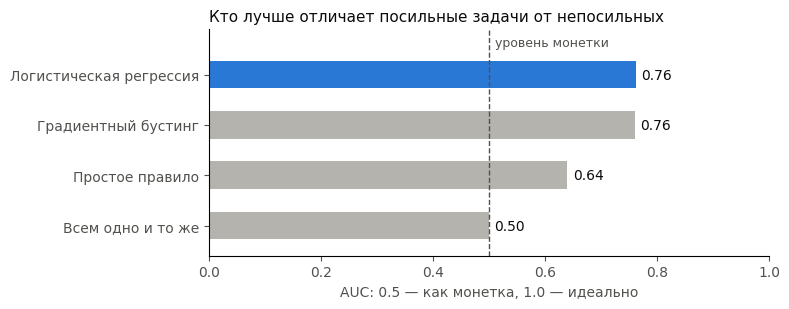

In [11]:
import matplotlib.pyplot as plt

BLUE, GRAY, INK, MUTED = "#2a78d6", "#b5b3ad", "#0b0b0b", "#52514e"
chosen = "Логистическая регрессия"

order = results.sort_values("AUC")
colors = [BLUE if name == chosen else GRAY for name in order.index]

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(order.index, order["AUC"], color=colors, height=0.55)
ax.axvline(0.5, color=MUTED, linestyle="--", linewidth=1)
ax.text(0.51, len(order) - 0.5, "уровень монетки", color=MUTED, fontsize=9, va="bottom")
for i, v in enumerate(order["AUC"]):
    ax.text(v + 0.01, i, f"{v:.2f}", va="center", color=INK, fontsize=10)

ax.set_xlim(0, 1)
ax.set_ylim(-0.6, len(order) - 0.1)
ax.set_xlabel("AUC: 0.5 — как монетка, 1.0 — идеально", color=MUTED)
ax.set_title("Кто лучше отличает посильные задачи от непосильных", loc="left", color=INK, fontsize=11)
ax.tick_params(colors=MUTED)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

**Выводы**

- По AUC модель заметно лучше простого правила: примерно 0.76 против 0.64. Игра стоит свеч.
- Метрика «угадано» обманчива: способ «всем одно и то же» уже угадывает около 71%, потому что в проверочной части большинство ответов верные. Поэтому главная метрика - AUC.
- Градиентный бустинг не лучше логистической регрессии. С этими четырьмя признаками сложная модель ничего не добавляет, поэтому дальше используем **логистическую регрессию**: она проще, быстрее и понятнее.

### Какой признак важнее всего

Проверяю так: по очереди перемешиваю значения одного признака, как будто модель перестала его видеть, и смотрю, насколько упадёт AUC. Чем сильнее падение, тем важнее признак. Направление влияния видно по знаку веса в логистической регрессии.

In [15]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(logreg, X_test, y_test, scoring="roc_auc", n_repeats=5, random_state=42)

importance = pd.DataFrame({
    "признак": [names[f] for f in features],
    "падение AUC": imp.importances_mean,
    "влияние на шанс": ["повышает" if c > 0 else "понижает" for c in logreg.coef_[0]],
}).sort_values("падение AUC", ascending=False).round(3)
importance

,признак,падение AUC,влияние на шанс
3,доля верных на задаче,0.145,повышает
0,доля верных (всего),0.029,повышает
1,доля верных (по теме),0.028,повышает
2,опыт по теме,-0.003,повышает


In [16]:
# доля верных ответов в зависимости от того, сколько задач по теме ученик уже решил
# (10 и больше объединяем в одну группу)
data.groupby(data["skill_count"].clip(upper=10))["correct"].agg(["mean", "count"]).round(3)

,mean,count
skill_count,,
0,0.603,35002
1,0.669,27400
2,0.683,22932
3,0.699,20648
4,0.690,18072
5,0.690,15477
6,0.685,13440
7,0.692,11656
8,0.684,10237


**Вывод.** Важнее всего трудность задачи: если перемешать долю верных ответов на задаче, AUC падает примерно на 0.15. Доля верных ученика в целом и по теме дают примерно по 0.03: они похожи, и модель может опираться на любую из них. Опыт по теме почти ничего не добавляет, его можно убрать или заменить, например, на давность последней попытки по теме.

Почему опыт по теме не помогает модели. Доля верных растёт с 60% до 70% за первые 3 задачи по теме, держится около 69% до 9 задач и падает до 65% у тех, кто решил 10 и больше. В ASSISTments тема заканчивается, когда ученик решает 3 задачи подряд, поэтому много задач по теме набирают те, кто в ней застрял. Связь получается «горкой», а логистическая регрессия ловит только прямую зависимость; к тому же часть информации об опыте уже есть в доле верных по теме.

## 7. Офлайн-проверка рекомендаций

Дать задачи живым ученикам здесь нельзя, но в проверочной части они решили много задач, и результаты известны. Смотрим, какие из этих задач выбрал бы каждый способ и как часто ученики с ними на самом деле справлялись. Цель - около 70%.

- **Бейзлайн** выбирает задачи из самой слабой темы ученика (тема определяется по данным обучения).
- **Модель** выбирает задачи, где предсказанный шанс от 60% до 80%.

In [12]:
test["p"] = predictions["Логистическая регрессия"]

# самая слабая тема каждого ученика по данным обучения
t = train.groupby(["user_id", "skill_name"])["correct"].agg(["mean", "count"]).reset_index()
t = t[t["count"] >= 3]
weakest = t.loc[t.groupby("user_id")["mean"].idxmin()]
weakest_topic = dict(zip(weakest["user_id"], weakest["skill_name"]))

# какие задачи выбрал бы каждый способ
test["baseline_pick"] = test["skill_name"] == test["user_id"].map(weakest_topic)
test["model_pick"] = test["p"].between(0.6, 0.8)

zone_results = pd.DataFrame({
    "задач": [test["baseline_pick"].sum(), test["model_pick"].sum()],
    "ученики решили": [test.loc[test["baseline_pick"], "correct"].mean(),
                       test.loc[test["model_pick"], "correct"].mean()],
}, index=["Бейзлайн: слабая тема", "Модель: шанс 60–80%"])
zone_results.round(3)

,задач,ученики решили
Бейзлайн: слабая тема,156,0.583
Модель: шанс 60–80%,20063,0.713


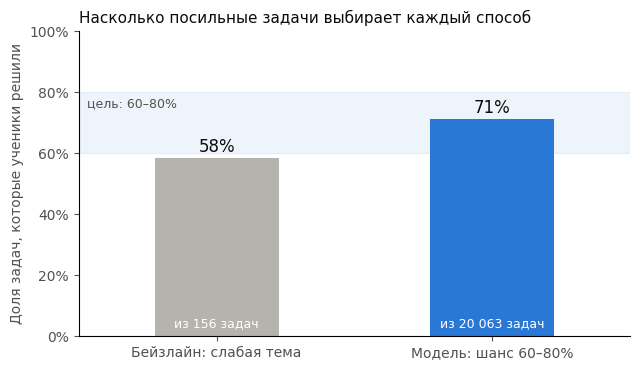

In [13]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.axhspan(0.6, 0.8, color=BLUE, alpha=0.08)
ax.text(-0.47, 0.785, "цель: 60–80%", color=MUTED, fontsize=9, ha="left", va="top")

ax.bar(zone_results.index, zone_results["ученики решили"], color=[GRAY, BLUE], width=0.45)
for i, (n, v) in enumerate(zip(zone_results["задач"], zone_results["ученики решили"])):
    ax.text(i, v + 0.02, f"{v:.0%}", ha="center", color=INK, fontsize=12)
    ax.text(i, 0.03, f"из {n:,} задач".replace(",", " "), ha="center", color="white", fontsize=9)

ax.set_ylim(0, 1)
ax.set_xlim(-0.5, 1.5)
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_ylabel("Доля задач, которые ученики решили", color=MUTED)
ax.set_title("Насколько посильные задачи выбирает каждый способ", loc="left", color=INK, fontsize=11)
ax.tick_params(colors=MUTED)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

**Выводы**

- Задачи, которые выбирает модель, ученики решают примерно в 71% случаев - почти ровно в целевой зоне. Значит, предсказанным шансам можно доверять.
- Задачи бейзлайна заметно труднее: ученики решают около 58%, то есть ошибаются примерно в 4 случаях из 10. Но таких задач в проверочной части мало (около 150), поэтому этот вывод предварительный.

## 8. Рекомендации модели для ученика

Функция объединяет обе идеи: берёт нерешённые задачи из трёх самых слабых тем ученика (как бейзлайн) и выбирает те, где шанс решить ближе всего к 70% (как модель).

In [14]:
def recommend_model(student_id, n=5, target=0.7):
    student = data[data["user_id"] == student_id]
    solved = set(student["problem_id"])

    # что ученик знает сейчас, по всей его истории
    user_acc = (student["correct"].sum() + 1) / (len(student) + 2)
    topics = student.groupby("skill_name")["correct"].agg(["sum", "count"])
    topics = topics[topics["count"] >= 3]
    topics["acc"] = (topics["sum"] + 1) / (topics["count"] + 2)
    weak = topics.sort_values("acc").head(3)

    # кандидаты: нерешённые задачи из трёх самых слабых тем
    cand = data[data["skill_name"].isin(weak.index) & ~data["problem_id"].isin(solved)]
    cand = cand[["problem_id", "skill_name"]].drop_duplicates("problem_id").copy()

    # те же четыре признака, что при обучении
    cand["user_acc"] = user_acc
    cand["skill_acc"] = cand["skill_name"].map(weak["acc"])
    cand["skill_count_log"] = np.log1p(cand["skill_name"].map(weak["count"]))
    cand["problem_acc"] = cand["problem_id"].map(problem_acc).fillna(mean_all)

    # шанс решить и отбор задач, где он ближе всего к 70%
    cand["шанс"] = logreg.predict_proba(cand[features])[:, 1]
    cand["отклонение"] = (cand["шанс"] - target).abs()
    best = cand.sort_values("отклонение").head(n)
    return ru(best[["problem_id", "skill_name", "шанс"]].round(2).reset_index(drop=True))

print("Ученик", student_id, "| бейзлайн:", recommend_simple(student_id))
display(recommend_model(student_id))
print("Ученик", second_id, "| бейзлайн:", recommend_simple(second_id))
display(recommend_model(second_id))

Ученик 79021 | бейзлайн: ('Reflection', [93011, 93000, 93001, 92995, 92985])


,задача,тема,шанс
0,86141,Least Common Multiple,0.64
1,86164,Least Common Multiple,0.63
2,86154,Least Common Multiple,0.61
3,86149,Least Common Multiple,0.61
4,86172,Least Common Multiple,0.61


Ученик 75169 | бейзлайн: ('Rotations', [93035, 93034, 93031, 93038, 93020])


,задача,тема,шанс
0,77440,Area Irregular Figure,0.7
1,77477,Area Irregular Figure,0.7
2,77510,Area Irregular Figure,0.7
3,77461,Area Irregular Figure,0.7
4,77551,Area Irregular Figure,0.7


## 9. Выводы, ограничения и что дальше

**Выводы**
- На реальных данных (около 275 тысяч ответов) модель на четырёх простых признаках предсказывает, решит ли ученик задачу, заметно лучше простого правила: AUC около 0.76 против 0.64.
- Простая логистическая регрессия не уступает градиентному бустингу, поэтому выбрана она.
- Задачи, которые модель считает посильными (шанс 60–80%), ученики действительно решают примерно в 71% случаев.
- Итоговая рекомендация сочетает идею репетитора (работать над слабыми темами) и модель (подбирать посильные задачи внутри них).

**Ограничения**
- Офлайн-проверка смотрит только на задачи, которые ученики и так решали. Помогают ли рекомендации учиться, можно узнать только A/B-тестом: одна группа учеников получает задачи от системы, другая - как обычно, и результаты сравниваются.
- Порядок ответов восстановлен по номеру записи `order_id`, как принято в работах с этим набором данных.
- Данные 2009–2010 годов, американская школьная программа.
- Целевой шанс 70% выбран из педагогической логики, а не подобран по данным.
- Условий задач в данных нет, поэтому модель не знает, о чём задача, только кто и как её решал.

**Что дальше**
- Спланировать A/B-тест на собственных учениках.
- Перенести расчёт признаков на PySpark для больших объёмов данных.
- Попробовать нейросеть на PyTorch, которая учитывает всю последовательность ответов ученика, и сравнить с логистической регрессией.
- Добавить объяснения и подсказки к задачам через GigaChat.
- Сделать демо-страницу на Streamlit.

# **То же самое на PySpark и SQL**:

In [ ]:
!pip install -q pyspark

In [17]:
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.window import Window

spark = SparkSession.builder.appName("recsys-tutor").getOrCreate()

raw = (spark.read
       .option("header", True)
       .option("inferSchema", True)
       .option("encoding", "ISO-8859-1")
       .option("escape", '"')
       .csv("data.csv"))
print("Строк в файле:", raw.count())

answers = (raw
           .select("order_id", "user_id", "problem_id", "skill_name", "correct")
           .where(F.col("skill_name").isNotNull() & (F.trim("skill_name") != "")))
print("Строк после чистки:", answers.count())

Строк в файле: 346860
Строк после чистки: 274590


In [18]:
answers.createOrReplaceTempView("answers")

spark.sql("""
    SELECT skill_name,
           ROUND(AVG(correct), 3) AS accuracy,
           COUNT(*) AS answers
    FROM answers
    GROUP BY skill_name
    HAVING COUNT(*) >= 100
    ORDER BY accuracy
    LIMIT 10
""").toPandas()

,skill_name,accuracy,answers
0,Rotations,0.136,427
1,Solving Systems of Linear Equations,0.192,234
2,Surface Area Cylinder,0.316,491
3,Percents,0.333,117
4,Algebraic Solving,0.368,389
5,Reflection,0.373,459
6,Mean,0.447,732
7,Unit Rate,0.465,3183
8,Write Linear Equation from Graph,0.478,5398
9,Area Irregular Figure,0.495,1760


In [19]:
by_user = Window.partitionBy("user_id").orderBy("order_id")
by_skill = Window.partitionBy("user_id", "skill_name").orderBy("order_id")
before = (Window.unboundedPreceding, -1)

feats = (answers
    .withColumn("user_count", F.row_number().over(by_user) - 1)
    .withColumn("user_right", F.coalesce(F.sum("correct").over(by_user.rowsBetween(*before)), F.lit(0)))
    .withColumn("user_acc", (F.col("user_right") + 1) / (F.col("user_count") + 2))
    .withColumn("skill_count", F.row_number().over(by_skill) - 1)
    .withColumn("skill_right", F.coalesce(F.sum("correct").over(by_skill.rowsBetween(*before)), F.lit(0)))
    .withColumn("skill_acc", (F.col("skill_right") + 1) / (F.col("skill_count") + 2))
    .withColumn("skill_count_log", F.log1p("skill_count")))

cols = ["user_acc", "skill_acc", "skill_count_log"]
spark_means = feats.agg(*[F.avg(c).alias(c) for c in cols]).toPandas().iloc[0]
pd.DataFrame({"PySpark": spark_means, "pandas": data[cols].mean()}).round(6)

,PySpark,pandas
user_acc,0.655270,0.655270
skill_acc,0.556704,0.556704
skill_count_log,1.834940,1.834940


**Итог.** На PySpark получилось то же, что в pandas: 274 590 строк после чистки, те же самые трудные темы в SQL-запросе, средние значения признаков совпадают до шестого знака.